In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
from scipy.signal import find_peaks
import datetime
import pickle

sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

import fracprolif as fp
from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
from call_cell_events import call_events #
from retrieve_cellState import retrieve_cellState #

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

ODE_DIR = Path(Path.home(),'ECM_mod_output/low_ODE_output')
if not ODE_DIR.exists():
    ODE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

SAVE_CELL_DATA = False

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv('model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [5]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [6]:
initial_concentrations

,Skp2_0,p21_0,p21p_0,cdh1act_0,cdh1inact_0,Myc_0,CycD_0,CycDp21_0,pRb_0,pRbp_0,...,CycEp21_0,CycA_0,CycAp21_0,CycB_0,CycBp21_0,Cdc20_0,BAX_0,BAXmBCL2_0,BH3_0,BH3BCL2_0
0,12,1,16,6,194,139,47,1,5,242,...,3,102,2,17,2,6,186,13,0,7


In [6]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv('model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


<Axes: xlabel='Time (h)', ylabel='Concentration'>

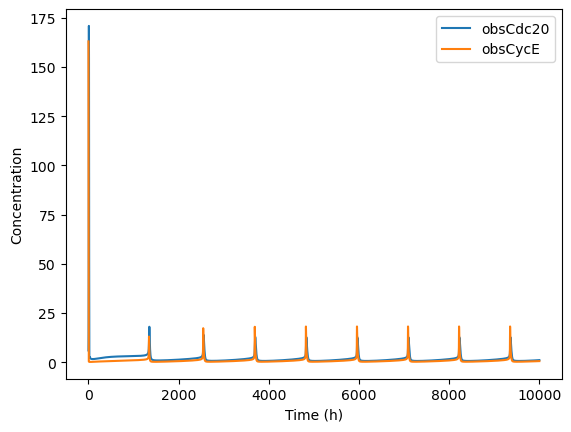

In [7]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 100000, 1000001)

model.parameters['AKT'].value = 0.3
model.parameters['ERK'].value = 0
model.parameters['FAK'].value = 0.4
# t = np.linspace(0, 50000, 500001)
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run() #deterministic simulation
y_out = sim_ode.observables

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,100000), legend=True)


In [8]:
Initial=[]
for j in range(len(model.observables)):
    name = model.observables[j].name
    val = sim_ode.all[name][-1]
    Initial.append(val)
Initial = [0 if i < 0 else i for i in Initial]

In [9]:
t = np.linspace(0, 1000000, 100001)
sim_ode = ScipyOdeSimulator(model, t, initials=Initial, verbose=False, compiler='python').run()


<Axes: xlabel='Time (h)', ylabel='Concentration'>

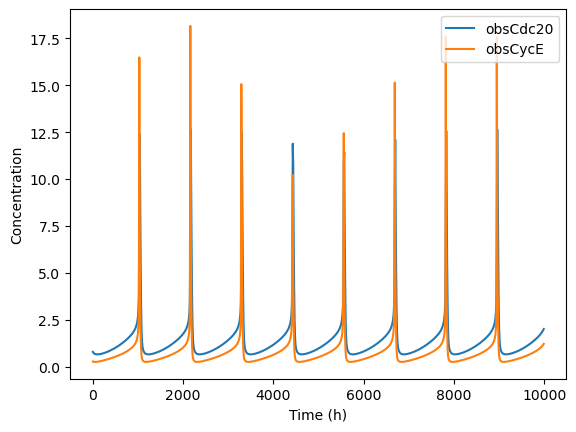

In [10]:
observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,1000), legend=True)

In [11]:
np.argmax(sim_ode.all['obsCdc20'][-10000:])

6081

In [12]:
init_off = Initial

In [13]:
Initial=[]
for j in range(len(model.observables)):
    name = model.observables[j].name
    max_ind = np.argmax(sim_ode.all['obsCdc20'][-10000:])
    val = sim_ode.all[name][(len(sim_ode.all[name])-10000)+max_ind]
    Initial.append(val)
Initial = [0 if i < 0 else i for i in Initial]

In [15]:
##ERL
treatment = 'ERL'
FAKs = list(np.linspace(0,0.4,51))
AKTs = list(np.linspace(0,0.6,51))
ERKs = 51*[1]
t = np.linspace(0, 100000, 1000001)
Initial = init_off

In [16]:
n=50
print(AKTs[n])
print(ERKs[n])
print(FAKs[n])

0.6
1
0.4


In [17]:
max_cdc20 = []
for n in range(51):  #len(FAKs)
    model.parameters['AKT'].value = AKTs[n]
    model.parameters['ERK'].value = ERKs[n]
    model.parameters['FAK'].value = FAKs[n]

    #run the ode using the old inits
    sim_ode = ScipyOdeSimulator(model, t, initials=Initial, verbose=False, compiler='python').run()
    y_out = sim_ode.observables
    Initial=[]
    for j in range(len(model.observables)):
        name = model.observables[j].name
        max_ind = np.argmax(sim_ode.all['obsCdc20'][-10000:])
        val = sim_ode.all[name][(len(sim_ode.all[name])-10000)+max_ind]
        Initial.append(val)
    Initial = [0 if i < 0 else i for i in Initial]

    peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)

    if len(peaks_cdc) > 7:
        variable_range=y_out[peaks_cdc[-6]:peaks_cdc[-1]]
    else:
        variable_range = y_out[90000:100000] 

    tmp = int(n)
    filename = Path(ODE_DIR,f'low_ERK1_{tmp:03}.csv')

    np.savetxt(filename, variable_range, delimiter=',')

    # Print progress on the same line
    sys.stdout.write(f'\rSaving {filename.name} ({n+1}/51)')
    sys.stdout.flush()
    

    
    

Saving low_ERK1_050.csv (51/51)

In [128]:
##ERL
treatment = 'ERL'
FAKs = list(np.linspace(0.4,0.6,51))
AKTs = list(np.linspace(0.3,0.6,51))
ERKs = 51*[0.1]
t = np.linspace(0, 100000, 1000001)
Initial = init_off

In [129]:
max_cdc20 = []
for n in range(51):  #len(FAKs)
    model.parameters['AKT'].value = AKTs[n]
    model.parameters['ERK'].value = ERKs[n]
    model.parameters['FAK'].value = FAKs[n]

    #run the ode using the old inits
    sim_ode = ScipyOdeSimulator(model, t, initials=Initial, verbose=False, compiler='python').run()
    y_out = sim_ode.observables
    Initial=[]
    for j in range(len(model.observables)):
        name = model.observables[j].name
        max_ind = np.argmax(sim_ode.all['obsCdc20'][-10000:])
        val = sim_ode.all[name][(len(sim_ode.all[name])-10000)+max_ind]
        Initial.append(val)
    Initial = [0 if i < 0 else i for i in Initial]

    peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)

    if len(peaks_cdc) > 7:
        variable_range=y_out[peaks_cdc[-6]:peaks_cdc[-1]]
    else:
        variable_range = y_out[90000:100000] 

    tmp = int(n)
    filename = Path(ODE_DIR,f'mid_ERK01_{tmp:03}.csv')

    np.savetxt(filename, variable_range, delimiter=',')

    # Print progress on the same line
    sys.stdout.write(f'\rSaving {filename.name} ({n+1}/51)')
    sys.stdout.flush()
    

    
    

Saving mid_ERK01_050.csv (51/51)

In [132]:
##ERL
treatment = 'ERL'
FAKs = list(np.linspace(0.6,1,51))
AKTs = 51*[0.6]
ERKs = 51*[0.1]
t = np.linspace(0, 100000, 1000001)
Initial = init_off

In [133]:
max_cdc20 = []
for n in range(51):  #len(FAKs)
    model.parameters['AKT'].value = AKTs[n]
    model.parameters['ERK'].value = ERKs[n]
    model.parameters['FAK'].value = FAKs[n]

    #run the ode using the old inits
    sim_ode = ScipyOdeSimulator(model, t, initials=Initial, verbose=False, compiler='python').run()
    y_out = sim_ode.observables
    Initial=[]
    for j in range(len(model.observables)):
        name = model.observables[j].name
        max_ind = np.argmax(sim_ode.all['obsCdc20'][-10000:])
        val = sim_ode.all[name][(len(sim_ode.all[name])-10000)+max_ind]
        Initial.append(val)
    Initial = [0 if i < 0 else i for i in Initial]

    peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)

    if len(peaks_cdc) > 7:
        variable_range=y_out[peaks_cdc[-6]:peaks_cdc[-1]]
    else:
        variable_range = y_out[90000:100000] 

    tmp = int(n)
    filename = Path(ODE_DIR,f'hi_ERK01_{tmp:03}.csv')

    np.savetxt(filename, variable_range, delimiter=',')

    # Print progress on the same line
    sys.stdout.write(f'\rSaving {filename.name} ({n+1}/51)')
    sys.stdout.flush()
    

    
    

Saving hi_ERK01_050.csv (51/51)

In [58]:
treatment = 'ERL'
FAKs = list(np.linspace(0,0.4,51))
AKTs = list(np.linspace(0,0.3,51))
ERKs = 51*[0]
t = np.linspace(0, 20000, 200001)
Initial = init_off

In [65]:
len(ERKs)

51

In [66]:
max_cdc20_cyc = []
for n in range(len(FAKs)):
    model.parameters['AKT'].value = AKTs[n]
    model.parameters['ERK'].value = ERKs[n]
    model.parameters['FAK'].value = FAKs[n]

    #run the ode using the old inits
    sim_ode = ScipyOdeSimulator(model, t, initials=Initial, verbose=False, compiler='python').run()
    y_out = sim_ode.observables
    Initial=[]
    for j in range(len(model.observables)):
        name = model.observables[j].name
        max_ind = np.argmax(sim_ode.all['obsCdc20'][-10000:])
        val = sim_ode.all[name][(len(sim_ode.all[name])-10000)+max_ind]
        Initial.append(val)
    Initial = [0 if i < 0 else i for i in Initial]

    peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)

    if len(peaks_cdc) > 7:
        variable_range=y_out[peaks_cdc[-6]:peaks_cdc[-1]]
    else:
        variable_range = y_out[90000:100000] 

    tmp = int(n)
    filename = Path(ODE_DIR,f'low_min_{tmp:03}.csv')

    print(f'Saving {filename}')
    np.savetxt(filename, variable_range, delimiter=',')
    

Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_000.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_001.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_002.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_003.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_004.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_005.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_006.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_007.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_008.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_009.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_010.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_011.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_012.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_output\low_min_013.csv
Saving C:\Users\olesk\ECM_mod_output\low_ODE_out

In [14]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import datetime
import glob
import joblib
import shutil
import umap
sys.path.insert(0, "cellular_cycle") # add path to the model

from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()


# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/')
RED_DIR = Path(Path.home(),'ECM_mod_output/UMAP')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files
SET_JPARAM = False

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

GENERATE_UMAP = False

In [15]:
if SET_JPARAM:
    filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and 'psoparam' in f]
else:
    filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_param_cycdi_0_0' in f]
filenames = sorted(filenames)

filenames_conds = [filenames[2], filenames[3], filenames[0],
                filenames[1], filenames[4], filenames[5]]

filenames_conds


[WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_soft_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_soft_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_int_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_int_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_stiff_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_stiff_erl_param_cycdi_0_0.csv')]

In [16]:
if SET_JPARAM:
    filenames_ode = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'ODE_sim' in f and 'psoparam' in f]
else:
    filenames_ode = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'ODE_sim' in f and '_param_cycdi_0_0' in f]
    
filenames_ode = sorted(filenames_ode)

filenames_conds_ode = [filenames_ode[2], filenames_ode[3], filenames_ode[0],
                filenames_ode[1], filenames_ode[4], filenames_ode[5]]

filenames_conds_ode


[WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_soft_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_soft_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_int_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_int_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_stiff_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_stiff_erl_param_cycdi_0_0.csv')]

In [17]:
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

if SET_JPARAM:
    rname = Path(RED_DIR, 'reducer_psoparams_20240513_0.1_0.1_4_0.5.sav')
else:
    rname = Path(RED_DIR, 'reducer_win_0.1_0.1_4_0.5.sav')

reducer = joblib.load(rname)

In [18]:
def calc_minmax(filenames, filenames_ode):
    # values to be replaced
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this now
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
        
    return max_prots, min_prots

In [19]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_{num}.png"), bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_norm_{num}.png"), bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [20]:
max_prots, min_prots = calc_minmax(filenames_conds, filenames_conds_ode)

In [21]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [22]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_conds, filenames_conds_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [23]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [24]:
# We don't need the full runs from the ODE solutions for the UMAP, we can use a shortened segment of the run
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames)
sp = 1
for n in range(len(filenames)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [25]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [26]:
FILE_LOC = Path(Path.home(),'ECM_mod_output/low_ODE_output')

filenames = [Path(FILE_LOC,f) for f in os.listdir(FILE_LOC)]    
    
all_odes = sorted(filenames)

In [27]:
FILE_LOC = Path(Path.home(),'ECM_mod_output/low_ODE_output')

filenames = [Path(FILE_LOC,f) for f in os.listdir(FILE_LOC) if "low_ERK1" in f]    
    
mid_odes = sorted(filenames)

In [28]:
len(mid_odes)

51

In [29]:
SAVE_DIR = Path(Path.home(),'ECM_mod_output/UMAP/low_ODE_embeddings')

if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

In [33]:
win_len = int(window/dt)
all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
all_prot_tmp_ode = np.empty((0,win_len*18))
all_time_tmp = np.empty((0,win_len))
all_time_at_tmp = np.empty((0,1))
#range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

for f in mid_odes:
    prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
    
    range_ind = np.arange(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt))
    #prot_tmp = prot_tmp/200
    for ii in range(18):
        prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
        #tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        #tmp_at = time_tmp2['time'].iloc[n]

        prot_re_tmp[ii,:] = np.array([tmp])
        #time_re_tmp[ii,:] = np.array([tmp_t])
        #time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1

    embedding_tmp = reducer.transform(prot_re_tmp)
    absolute_path = f.absolute().as_posix()    
    split_s = absolute_path.split('.')
    split_ss = split_s[0].split('/')

    name = 'embedding_'+split_ss[-1]+'.csv'
    
    np.savetxt(Path(SAVE_DIR, name), embedding_tmp, delimiter=',', fmt='%f')

In [71]:
win_len = int(window/dt)
all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
all_prot_tmp_ode = np.empty((0,win_len*18))
all_time_tmp = np.empty((0,win_len))
all_time_at_tmp = np.empty((0,1))
#range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

for f in low_odes:
    prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
    
    range_ind = np.arange(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt))
    #prot_tmp = prot_tmp/200
    for ii in range(18):
        prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
        #tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        #tmp_at = time_tmp2['time'].iloc[n]

        prot_re_tmp[ii,:] = np.array([tmp])
        #time_re_tmp[ii,:] = np.array([tmp_t])
        #time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1

    embedding_tmp = reducer.transform(prot_re_tmp)
    absolute_path = f.absolute().as_posix()    
    split_s = absolute_path.split('.')
    split_ss = split_s[0].split('/')

    name = 'embedding_'+split_ss[-1]+'.csv'
    
    np.savetxt(Path(SAVE_DIR, name), embedding_tmp, delimiter=',', fmt='%f')

In [29]:
LYAP_filepaths = [str(Path(SAVE_DIR, f)) for f in os.listdir(SAVE_DIR) if '.csv' in f]  

In [30]:
hi_embed_00 = [f for f in LYAP_filepaths if 'hi_ERK00' in f]
hi_embed_00.sort()
hi_embed_01 = [f for f in LYAP_filepaths if 'hi_ERK01' in f]
hi_embed_01.sort()
hi_embed_02 = [f for f in LYAP_filepaths if 'hi_ERK02' in f]
hi_embed_02.sort()

In [31]:
low_embed_00 = [f for f in LYAP_filepaths if 'low_ERK00' in f]
low_embed_00.sort()
low_embed_01 = [f for f in LYAP_filepaths if 'low_ERK01' in f]
low_embed_01.sort()
low_embed_02 = [f for f in LYAP_filepaths if 'low_ERK02' in f]
low_embed_02.sort()

In [32]:
mid_embed_00 = [f for f in LYAP_filepaths if 'mid_ERK00' in f]
mid_embed_00.sort()
mid_embed_01 = [f for f in LYAP_filepaths if 'mid_ERK01' in f]
mid_embed_01.sort()
mid_embed_02 = [f for f in LYAP_filepaths if 'mid_ERK02' in f]
mid_embed_02.sort()

In [33]:
hi_embed_00[:5]

['C:\\Users\\olesk\\ECM_mod_output\\UMAP\\low_ODE_embeddings\\embedding_hi_ERK00_000.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\UMAP\\low_ODE_embeddings\\embedding_hi_ERK00_001.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\UMAP\\low_ODE_embeddings\\embedding_hi_ERK00_002.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\UMAP\\low_ODE_embeddings\\embedding_hi_ERK00_003.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\UMAP\\low_ODE_embeddings\\embedding_hi_ERK00_004.csv']

In [34]:
import matplotlib.cm as cm
viridis = cm.get_cmap('viridis', 51)

In [35]:
size = (12,4)
xmin = -10
xmax = 15
ymin = 0
ymax = 18
wid = 1

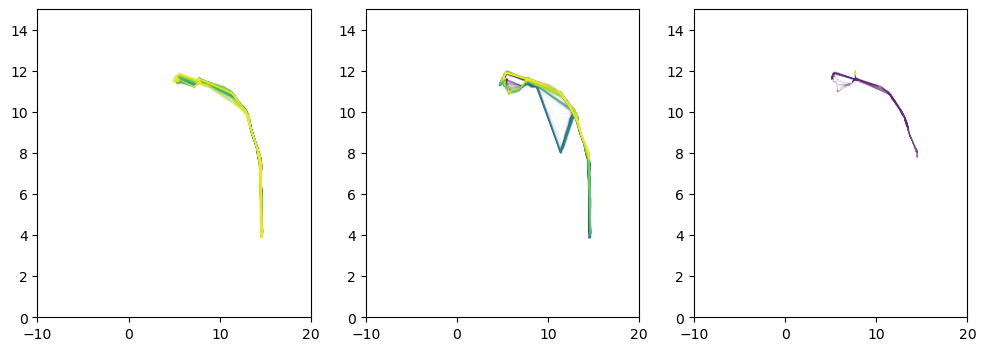

In [36]:
fig, axes = plt.subplots(1, 3, figsize=size, gridspec_kw={'width_ratios': [1, 1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

for i, f in enumerate(low_embed_00):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=viridis(i), lw=0.05, alpha=0.5)
    axes[0].set_xlim(-10, 20)
    axes[0].set_ylim(0, 15)

for i, f in enumerate(mid_embed_00):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=viridis(i), lw=0.05, alpha=0.5)
    axes[1].set_xlim(-10, 20)
    axes[1].set_ylim(0, 15)

for i, f in enumerate(hi_embed_00):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    axes[2].plot(tmp_emb[:,0], tmp_emb[:,1], color=viridis(i), lw=0.05, alpha=0.5)
    axes[2].set_xlim(-10, 20)
    axes[2].set_ylim(0, 15)


(0.0, 15.0)

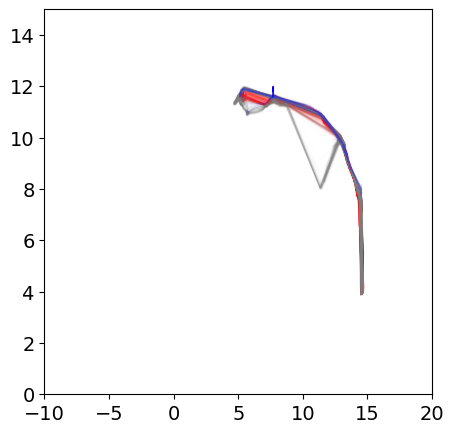

In [41]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_conds))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_conds))
n=1
n1=2
# plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], 
#          lw=0.05, alpha=0.7, c='gray')

for i, f in enumerate(low_embed_00):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    plt.plot(tmp_emb[:,0], tmp_emb[:,1], color='red', lw=0.05, alpha=0.2)

for i, f in enumerate(mid_embed_00):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    plt.plot(tmp_emb[:,0], tmp_emb[:,1], color='grey', lw=0.05, alpha=0.2)

for i, f in enumerate(hi_embed_00):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    plt.plot(tmp_emb[:,0], tmp_emb[:,1], color='blue', lw=0.05, alpha=0.2)

plt.xlim(-10, 20)
plt.ylim(0, 15)


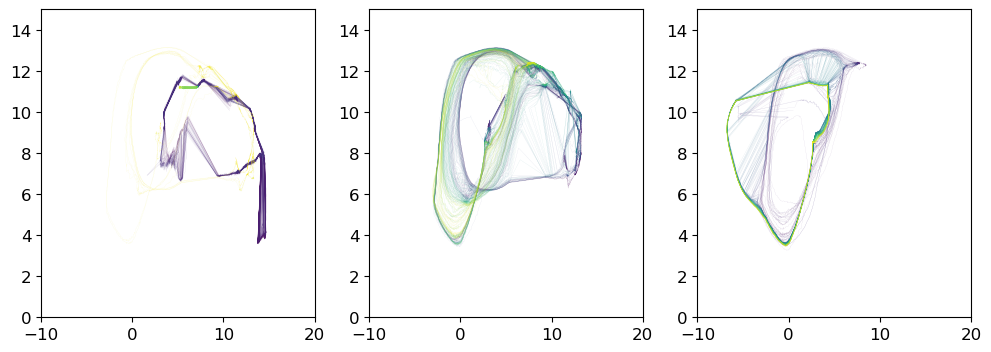

In [167]:
fig, axes = plt.subplots(1, 3, figsize=size, gridspec_kw={'width_ratios': [1, 1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

for i, f in enumerate(low_embed_01):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=viridis(i), lw=0.05, alpha=0.5)
    axes[0].set_xlim(-10, 20)
    axes[0].set_ylim(0, 15)

for i, f in enumerate(mid_embed_01):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=viridis(i), lw=0.05, alpha=0.5)
    axes[1].set_xlim(-10, 20)
    axes[1].set_ylim(0, 15)

for i, f in enumerate(hi_embed_01):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    axes[2].plot(tmp_emb[:,0], tmp_emb[:,1], color=viridis(i), lw=0.05, alpha=0.5)
    axes[2].set_xlim(-10, 20)
    axes[2].set_ylim(0, 15)


(0.0, 15.0)

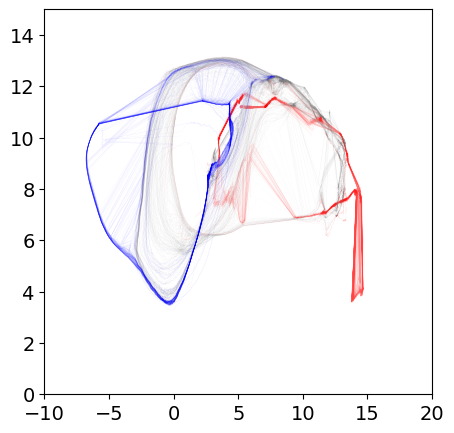

In [42]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_conds))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_conds))
n=1
n1=2
# plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], 
#          lw=0.05, alpha=0.7, c='gray')

for i, f in enumerate(low_embed_01):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    plt.plot(tmp_emb[:,0], tmp_emb[:,1], color='red', lw=0.05, alpha=0.2)

for i, f in enumerate(mid_embed_01):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    plt.plot(tmp_emb[:,0], tmp_emb[:,1], color='grey', lw=0.05, alpha=0.2)

for i, f in enumerate(hi_embed_01):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    plt.plot(tmp_emb[:,0], tmp_emb[:,1], color='blue', lw=0.05, alpha=0.2)

plt.xlim(-10, 20)
plt.ylim(0, 15)


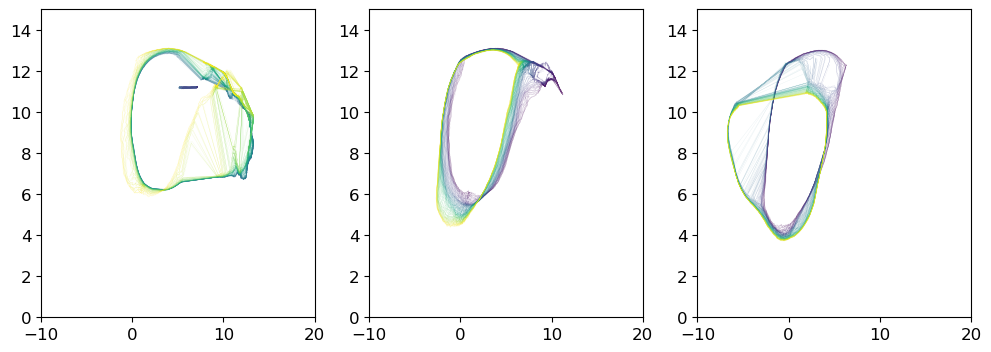

In [168]:
fig, axes = plt.subplots(1, 3, figsize=size, gridspec_kw={'width_ratios': [1, 1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

for i, f in enumerate(low_embed_02):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=viridis(i), lw=0.05, alpha=0.5)
    axes[0].set_xlim(-10, 20)
    axes[0].set_ylim(0, 15)

for i, f in enumerate(mid_embed_02):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=viridis(i), lw=0.05, alpha=0.5)
    axes[1].set_xlim(-10, 20)
    axes[1].set_ylim(0, 15)

for i, f in enumerate(hi_embed_02):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    axes[2].plot(tmp_emb[:,0], tmp_emb[:,1], color=viridis(i), lw=0.05, alpha=0.5)
    axes[2].set_xlim(-10, 20)
    axes[2].set_ylim(0, 15)


(0.0, 15.0)

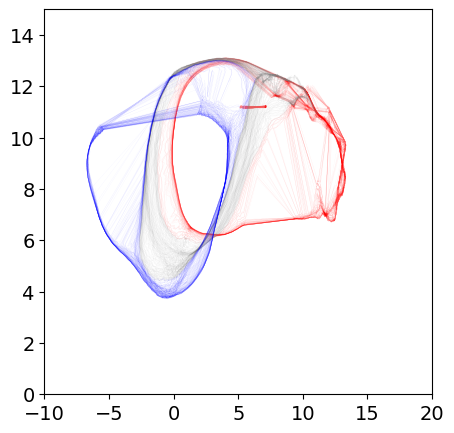

In [43]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,...
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_conds))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_conds))
n=1
n1=2
# plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], 
#          lw=0.05, alpha=0.7, c='gray')

for i, f in enumerate(low_embed_02):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    plt.plot(tmp_emb[:,0], tmp_emb[:,1], color='red', lw=0.05, alpha=0.2)

for i, f in enumerate(mid_embed_02):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    plt.plot(tmp_emb[:,0], tmp_emb[:,1], color='grey', lw=0.05, alpha=0.2)

for i, f in enumerate(hi_embed_02):
    tmp_emb = np.genfromtxt(f, delimiter=',')
    plt.plot(tmp_emb[:,0], tmp_emb[:,1], color='blue', lw=0.05, alpha=0.2)

plt.xlim(-10, 20)
plt.ylim(0, 15)


In [96]:
prot_tmp = pd.read_csv(Path("C:/Users/olesk/ECM_mod_output/ODE_sim_soft_erl_param_cycdi_0_0.csv"), header=None, usecols = range(0,19))
prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
"Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
"cycB", "cycB-p21", "cdc20"]
prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
prot_tmp['cdc20']

0         6.000000
1         6.020723
2         6.076371
3         6.163339
4         6.278565
            ...   
199996    3.200740
199997    3.198574
199998    3.196424
199999    3.194294
200000    3.192181
Name: cdc20, Length: 200001, dtype: float64

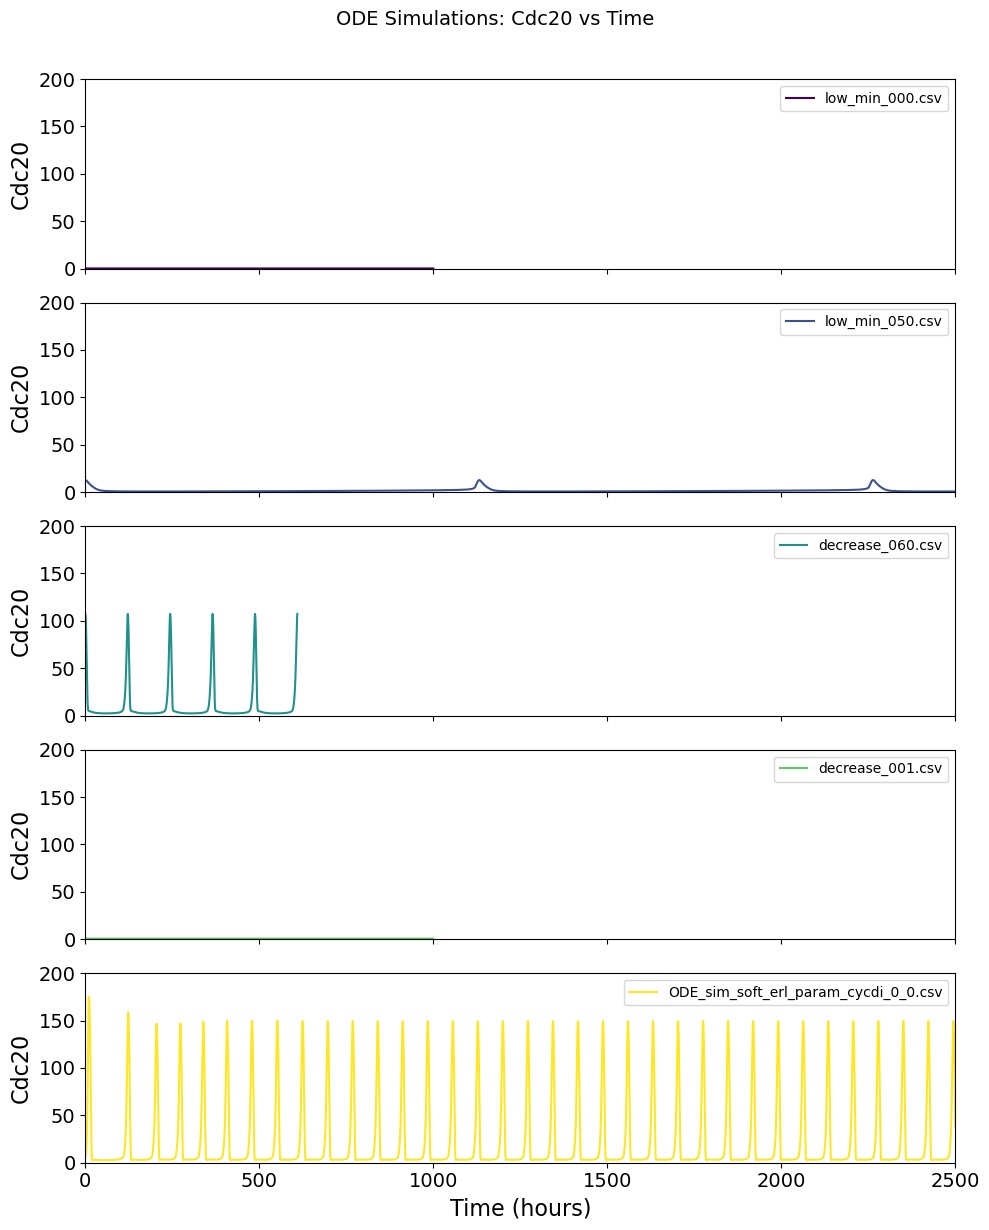

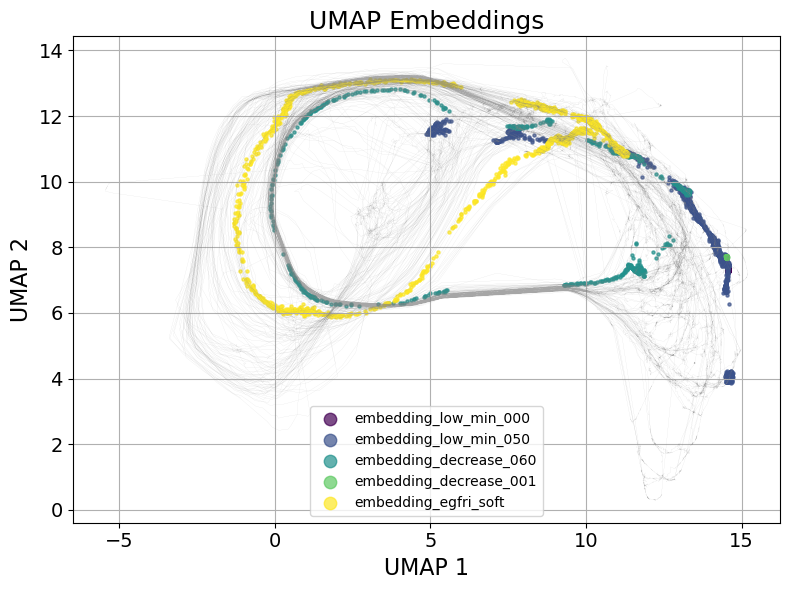

In [102]:
# Time vector
t = np.linspace(0, 100000, 1000001)

# ODE and UMAP file paths
ode_files = [
    Path("C:/Users/olesk/ECM_mod_output/low_ODE_output/low_min_000.csv"),
    Path("C:/Users/olesk/ECM_mod_output/low_ODE_output/low_min_050.csv"),
    Path("C:/Users/olesk/ECM_mod_output/low_ODE_output/decrease_060.csv"),
    Path("C:/Users/olesk/ECM_mod_output/low_ODE_output/decrease_001.csv"),
    Path("C:/Users/olesk/ECM_mod_output/ODE_sim_soft_erl_param_cycdi_0_0.csv")
]

umap_files = [
    Path("C:/Users/olesk/ECM_mod_output/UMAP/low_ODE_embeddings/embedding_low_min_000.csv"),
    Path("C:/Users/olesk/ECM_mod_output/UMAP/low_ODE_embeddings/embedding_low_min_050.csv"),
    Path("C:/Users/olesk/ECM_mod_output/UMAP/low_ODE_embeddings/embedding_decrease_060.csv"),
    Path("C:/Users/olesk/ECM_mod_output/UMAP/low_ODE_embeddings/embedding_decrease_001.csv"),
    # Last one is handled in-memory later
]

# Plotting ODE traces (limited to 2500 hours)
max_time_hours = 2500
time_step = t[1] - t[0]  # assuming uniform spacing
max_index = int(max_time_hours / time_step)

# Plotting ODE traces
num_ode = len(ode_files)
fig, axs = plt.subplots(num_ode, 1, figsize=(10, 2.5 * num_ode), sharex=True)
viridis = cm.get_cmap('viridis', len(umap_files) + 1)

for i, file in enumerate(ode_files):
    prot_tmp = pd.read_csv(file, header=None, usecols = range(0,19))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])

    trace = prot_tmp["cdc20"] 
    time_subset = t[:len(trace)]
    axs[i].plot(time_subset, trace, label=file.name, color=viridis(i))
    axs[i].set_xlim(0, 2500)
    axs[i].set_ylim(0, 200)
    axs[i].set_ylabel('Cdc20')
    axs[i].legend(loc='upper right')

axs[-1].set_xlabel('Time (hours)')
fig.suptitle('ODE Simulations: Cdc20 vs Time', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# Plotting UMAP embeddings
plt.figure(figsize=(8, 6))

n=1
n1=2
plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], 
         lw=0.05, alpha=0.7, c='gray')

# Load and plot UMAP CSVs
for i, file in enumerate(umap_files):
    df = pd.read_csv(file, header=None)
    plt.scatter(df.iloc[:, 0], df.iloc[:, 1], s=5, alpha=0.7, label=file.stem, color=viridis(i))

# Handle the last UMAP slice from in-memory array
trk_len_ode = int(len(embedding_all_prot_ode) / len(filenames_conds))
embedding_slice = embedding_all_prot_ode[1 * trk_len_ode : 2 * trk_len_ode, :]
plt.scatter(embedding_slice[:, 0], embedding_slice[:, 1], s=5, alpha=0.7, label='embedding_egfri_soft', color=viridis(len(umap_files)))

plt.legend(markerscale=4, loc='best')
plt.title("UMAP Embeddings")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.grid(True)
plt.tight_layout()
plt.show()


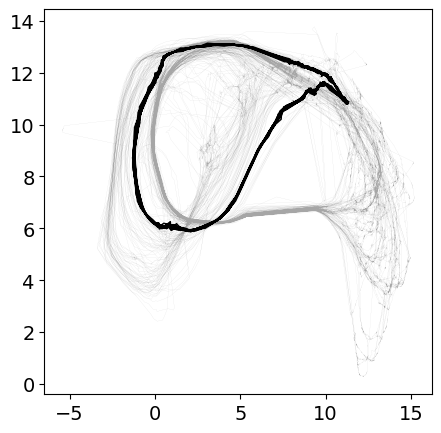

In [78]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_conds))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_conds))
n=1
n1=2
plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], 
         lw=0.05, alpha=0.7, c='gray')
plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], 
         lw=1, alpha=1, c='black')
# plt.scatter(embedding_off_00_end[1999:,0], embedding_off_00_end[1999:,1], alpha=0.5)
# plt.scatter(embedding_off_05_end[1999:,0], embedding_off_05_end[1999:,1], c='purple', alpha=0.5)
# plt.scatter(embedding_off_10_end[1999:,0], embedding_off_10_end[1999:,1], c='green', alpha=0.5)
# plt.scatter(embedding_off_15_end[1999:,0], embedding_off_15_end[1999:,1], c='green', alpha=0.5)
# plt.scatter(embedding_off_20_end[1999:,0], embedding_off_20_end[1999:,1], c='green', alpha=0.5)
# plt.scatter(embedding_off_25_end[1999:,0], embedding_off_25_end[1999:,1], c='green', alpha=0.5)
# plt.scatter(embedding_off_30_end[1999:,0], embedding_off_30_end[1999:,1], c='blue', alpha=0.5)
# plt.scatter(embedding_off_low_end[1999:,0], embedding_off_low_end[1999:,1], c='black', alpha=0.5)
# plt.plot(embedding_on_60_end[:,0], embedding_on_60_end[:,1], c='red', ls='--')
# plt.plot(embedding_off_20_end[:,0], embedding_off_20_end[:,1], c='green')


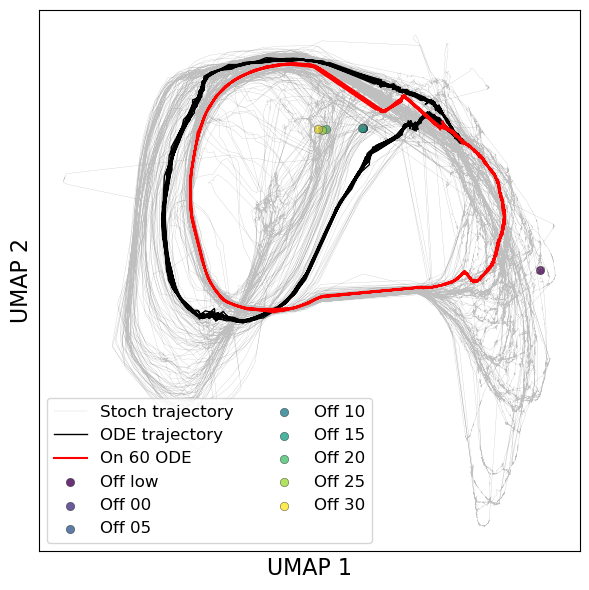

In [89]:
import matplotlib.pyplot as plt
import numpy as np

# 1) global style tweaks
size = (6, 6)
line_alpha = 0.5
scatter_alpha = 0.8

params = {
    'figure.figsize': size,
    'axes.titley': 1,
    'axes.titlepad': 5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'axes.edgecolor': "black",
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
}
plt.rcParams.update(params)

# 2) set up figure & axis
fig, ax = plt.subplots()

# 3) plot the trajectories
trk_len = len(embedding_all_prot) // len(filenames_conds)
trk_len_ode = len(embedding_all_prot_ode) // len(filenames_conds)
n, n1 = 1, 2

ax.plot(
    embedding_all_prot[n*trk_len:n1*trk_len, 0],
    embedding_all_prot[n*trk_len:n1*trk_len, 1],
    lw=0.2, alpha=line_alpha, color='gray',
    label='Stoch trajectory'
)
ax.plot(
    embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode, 0],
    embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode, 1],
    lw=1.0, alpha=1.0, color='black',
    label='ODE trajectory'
)
ax.plot(
    embedding_on_60_end[:, 0],
    embedding_on_60_end[:, 1],
    linestyle='-', color='red',
    label='On 60 ODE'
)

# 4) scatter endpoints with a gradient of colors
endpoints = {
    'Off low': embedding_off_low_end[1999:],
    'Off 00': embedding_off_00_end[1999:],
    'Off 05': embedding_off_05_end[1999:],
    'Off 10': embedding_off_10_end[1999:],
    'Off 15': embedding_off_15_end[1999:],
    'Off 20': embedding_off_20_end[1999:],
    'Off 25': embedding_off_25_end[1999:],
    'Off 30': embedding_off_30_end[1999:],
}
cmap = plt.cm.viridis
colors = cmap(np.linspace(0, 1, len(endpoints)))

for (label, data), color in zip(endpoints.items(), colors):
    ax.scatter(
        data[:, 0],
        data[:, 1],
        color=color,
        alpha=scatter_alpha,
        edgecolor='k',
        linewidth=0.3,
        label=label
    )

# 5) finalize
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.legend(loc='lower left', fontsize=12, frameon=True, ncol=2)

plt.tight_layout()
plt.show()


In [100]:
initial_concentrations_on_60 = initial_concentrations
initial_concentrations_off_60 = initial_concentrations
initial_concentrations_off_00 = initial_concentrations

In [101]:
for n in range(23):
    initial_concentrations_on_60.iloc[0,n] = init_on_60[n]
    initial_concentrations_off_60.iloc[0,n] = init_off_60[n]
    initial_concentrations_off_00.iloc[0,n] = init_off_00[n]

In [104]:
initial_concentrations_on_60.to_csv(os.getcwd() + '/model_data/initial_concentrations_on_60.csv', index=False)
initial_concentrations_off_60.to_csv(os.getcwd() + '/model_data/initial_concentrations_off_60.csv', index=False)
initial_concentrations_off_00.to_csv(os.getcwd() + '/model_data/initial_concentrations_off_00.csv', index=False)

In [80]:
joblib.dump(embedding_off_low_end, Path(SAVE_DIR, f'embedding_off_low_end.sav'))
joblib.dump(embedding_off_00_end, Path(SAVE_DIR, f'embedding_off_00_end.sav'))
joblib.dump(embedding_off_05_end, Path(SAVE_DIR, f'embedding_off_05_end.sav'))
joblib.dump(embedding_off_10_end, Path(SAVE_DIR, f'embedding_off_10_end.sav'))
joblib.dump(embedding_off_15_end, Path(SAVE_DIR, f'embedding_off_15_end.sav'))
joblib.dump(embedding_off_20_end, Path(SAVE_DIR, f'embedding_off_20_end.sav'))
joblib.dump(embedding_off_25_end, Path(SAVE_DIR, f'embedding_off_25_end.sav'))
joblib.dump(embedding_off_30_end, Path(SAVE_DIR, f'embedding_off_30_end.sav'))
joblib.dump(embedding_on_60_end, Path(SAVE_DIR, f'embedding_on_60_end.sav'))


['C:\\Users\\olesk\\ECM_mod_output\\embedding_on_60_end.sav']